# Brain Tumor MRI — Dataset Exploration

Goals (project step 1 — *Understand the Dataset*):
1. Count the categories (tumour types) and images per class, and check for class imbalance.
2. Look at sample images from each class.
3. Check image resolution consistency.
4. Look at pixel-intensity distributions.
5. Preview the augmentations used for training.

In [1]:
import sys
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"
CLASSES = sorted(p.name for p in (DATA / "Training").iterdir() if p.is_dir())
CLASSES

['glioma', 'meningioma', 'notumor', 'pituitary']

## 1. Images per class

In [2]:
counts = pd.DataFrame({
    split: {c: len(list((DATA / split / c).glob("*.jpg"))) for c in CLASSES}
    for split in ["Training", "Testing"]
})
counts.loc["total"] = counts.sum()
counts

,Training,Testing
glioma,1321,300
meningioma,1339,306
notumor,1595,405
pituitary,1457,300
total,5712,1311


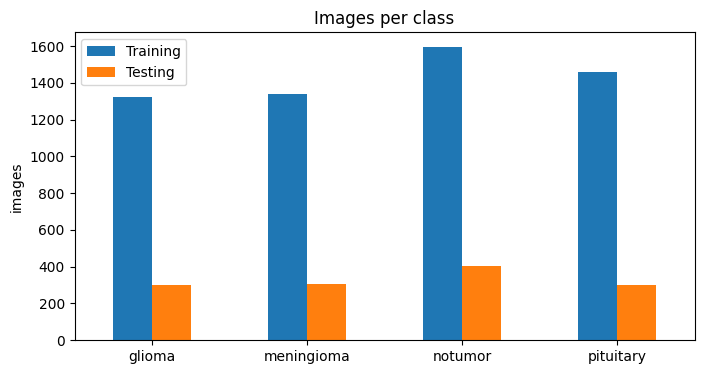

Imbalance ratio (largest / smallest class): 1.21


In [3]:
ax = counts.drop("total").plot.bar(figsize=(8, 4), rot=0, title="Images per class")
ax.set_ylabel("images")
plt.show()

train = counts.drop("total")["Training"]
print(f"Imbalance ratio (largest / smallest class): {train.max() / train.min():.2f}")

The classes are close to balanced (largest/smallest ≈ 1.2), so no resampling or class weights are needed.
`notumor` is the largest class in both splits.

## 2. Sample images

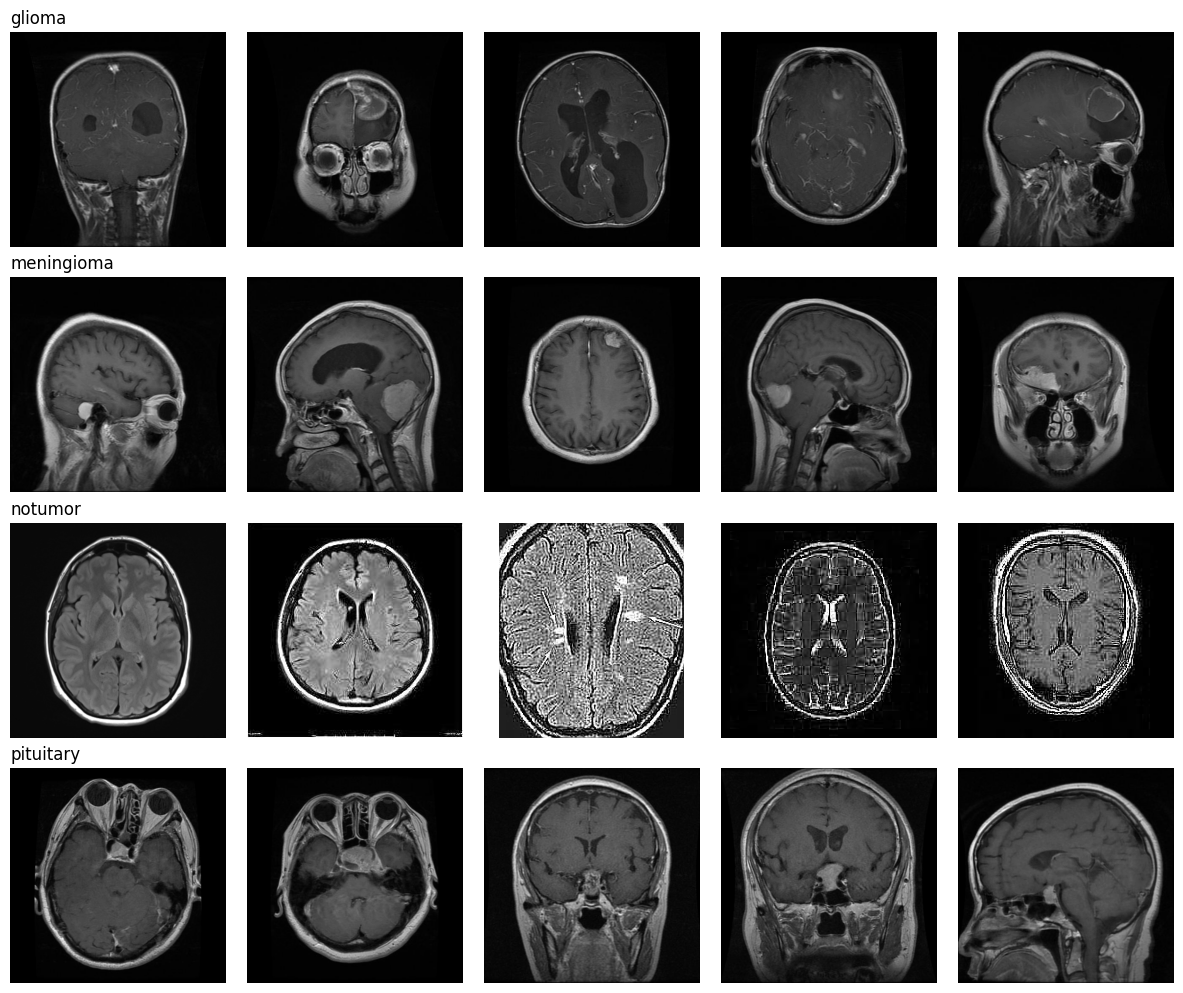

In [4]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(12, 10))
for row, c in enumerate(CLASSES):
    files = sorted((DATA / "Training" / c).glob("*.jpg"))
    for col, f in enumerate(rng.choice(files, 5, replace=False)):
        axes[row, col].imshow(Image.open(f).convert("L"), cmap="gray")
        axes[row, col].axis("off")
    axes[row, 0].set_title(c, loc="left", fontsize=12)
plt.tight_layout()
plt.show()

## 3. Image resolution

In [5]:
records = []
for split in ["Training", "Testing"]:
    for c in CLASSES:
        for f in (DATA / split / c).glob("*.jpg"):
            with Image.open(f) as im:
                records.append({"split": split, "class": c, "width": im.width,
                                "height": im.height, "mode": im.mode})
sizes = pd.DataFrame(records)
print("Distinct resolutions:", sizes.groupby(["width", "height"]).ngroups)
print("Colour modes:", Counter(sizes["mode"]))
sizes.groupby("class")[["width", "height"]].describe().round(0)

Distinct resolutions: 387
Colour modes: Counter({'RGB': 3926, 'L': 3093, 'RGBA': 3, 'P': 1})


width                                                    height  \
             count   mean    std    min    25%    50%    75%     max   count   
class                                                                          
glioma      1621.0  512.0    0.0  512.0  512.0  512.0  512.0   512.0  1621.0   
meningioma  1645.0  483.0   90.0  174.0  512.0  512.0  512.0  1275.0  1645.0   
notumor     2000.0  306.0  159.0  150.0  220.0  232.0  359.0  1920.0  2000.0   
pituitary   1757.0  509.0   46.0  201.0  512.0  512.0  512.0  1365.0  1757.0   

                                                              
             mean    std    min    25%    50%    75%     max  
class                                                         
glioma      512.0    0.0  512.0  512.0  512.0  512.0   512.0  
meningioma  486.0   85.0  195.0  512.0  512.0  512.0  1427.0  
notumor     313.0  149.0  168.0  225.0  243.0  393.0  1446.0  
pituitary   509.0   46.0  202.0  512.0  512.0  512.0  1365.0

In [6]:
sizes.value_counts(["width", "height"]).head(10).to_frame("images")

,,images
width,height,
512,512,4742
225,225,332
630,630,90
236,236,81
201,251,58
228,221,51
232,217,50
300,168,49
442,442,46


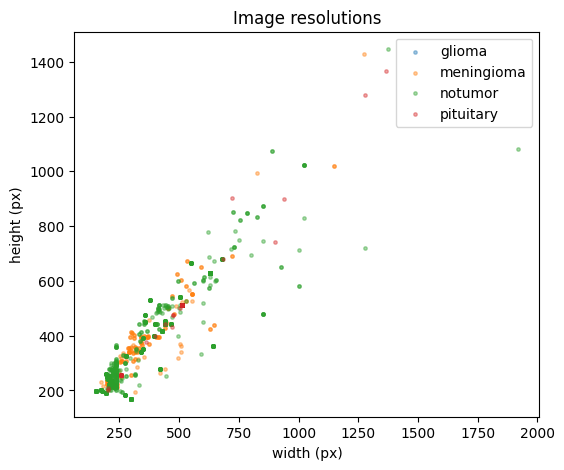

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
for c in CLASSES:
    s = sizes[sizes["class"] == c]
    ax.scatter(s["width"], s["height"], s=6, alpha=0.4, label=c)
ax.set(xlabel="width (px)", ylabel="height (px)", title="Image resolutions")
ax.legend()
plt.show()

Resolutions vary widely and are not always square, and images come in both grayscale and RGB modes.
That is why preprocessing converts every image to RGB and resizes it to **224×224**, then scales pixels
to 0–1 and normalises with ImageNet statistics.

## 4. Pixel-intensity distribution

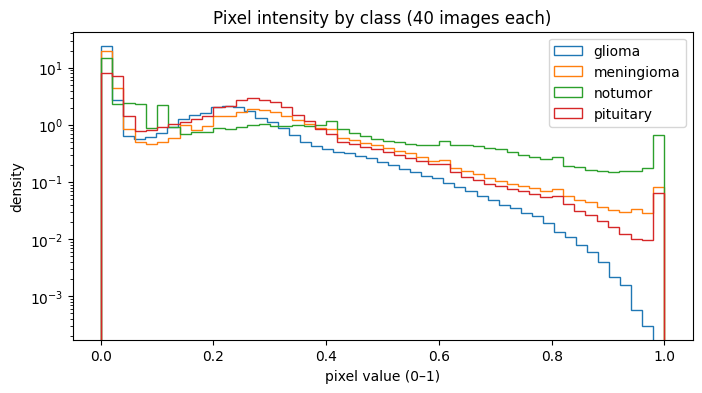

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for c in CLASSES:
    files = sorted((DATA / "Training" / c).glob("*.jpg"))
    pixels = np.concatenate([
        np.asarray(Image.open(f).convert("L").resize((224, 224))).ravel() / 255.0
        for f in rng.choice(files, 40, replace=False)
    ])
    ax.hist(pixels, bins=50, histtype="step", density=True, label=c)
ax.set(xlabel="pixel value (0–1)", ylabel="density", title="Pixel intensity by class (40 images each)")
ax.set_yscale("log")
ax.legend()
plt.show()

Most pixels are dark background; the classes differ mainly in the mid-intensity brain-tissue range.

## 5. Augmentation preview

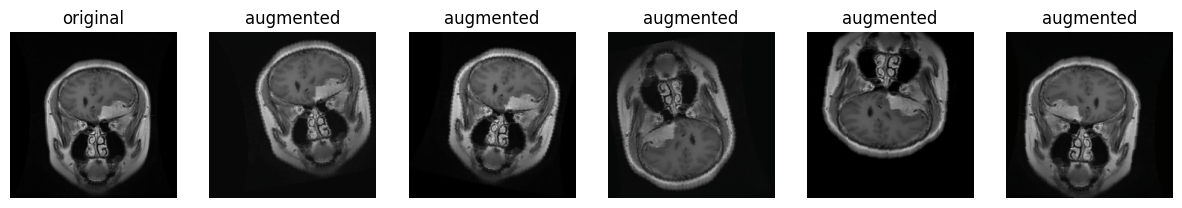

In [9]:
from data_preprocessing import train_transform, IMAGENET_MEAN, IMAGENET_STD

def denormalise(t):
    img = t.numpy().transpose(1, 2, 0) * IMAGENET_STD + IMAGENET_MEAN
    return np.clip(img, 0, 1)

sample = Image.open(sorted((DATA / "Training" / "meningioma").glob("*.jpg"))[0]).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(sample.resize((224, 224)))
axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(denormalise(train_transform(sample)))
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.show()

## Summary

- **4 classes**: glioma, meningioma, notumor, pituitary — 5,712 training and 1,311 test images.
- Classes are roughly balanced, so plain cross-entropy is fine.
- Image sizes and colour modes vary, so everything is converted to RGB, resized to 224×224 and normalised.
- 20% of the Training folder is held out for validation; the Testing folder is used only for the final evaluation.
- Training augmentation: random crop/zoom, horizontal + vertical flips, rotation, shifts, brightness/contrast jitter.